Homework 9 – Cartography with Matplotlib

By Antoaneta Chakarova for Geog592

10/29/2026

In [13]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages


In [14]:
url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip"
counties = gpd.read_file(url)
nc_counties = counties[counties["STATEFP"] == "37"].to_crs(6543).copy()
nc_counties = nc_counties.sort_values("NAME").reset_index(drop=True)

In [15]:
mines = pd.read_csv("NCMiningPermits.csv")
mines = mines.dropna(subset=["LONGITUDE", "LATITUDE"])

#longitude and latitude become map points, then use the same CRS as the counties
mines_points = gpd.GeoDataFrame(mines, geometry=gpd.points_from_xy(mines["LONGITUDE"], mines["LATITUDE"]), crs="EPSG:4326")
mines_points = mines_points.to_crs(nc_counties.crs)
mines_points.head()


,X,Y,PERMIT_NUMBER,Permit_number_text,Permittee_Bus_Name,LOCATION_NAME,FIPS_COUNTY_DESC,REGION_NAME,River_Basin_Name,ORIG_ISSUE_DATE,...,NEW_ACRES_RECLAIMED,ACRES_CURRENT_TOTAL,LAST_UPDATE_DATE,INSPECTED_BY,LAST_NOD_DATE,LAST_NOV_DATE,Last_Inspection_Date,NEXT_SCHEDULED_INSPECTION_DATE,FID,geometry
0,-8.535774e+06,4.310923e+06,NaN,'16-04,NaN,Elmer Overton Pit,Chowan,Washington Regional Office,Chowan,1982/10/22 00:00:00+00,...,0.0,0.0,2003/10/08 00:00:00+00,Unknown,NaN,1987/03/30 00:00:00+00,1987/11/05 00:00:00+00,9999/09/09 00:00:00+00,1,POINT (2686099.504 854162.556)
1,-8.539819e+06,4.325280e+06,NaN,'16-05,David Harrell Dba Dirt Boys,David Harrell Pit,Chowan,Washington Regional Office,Chowan,1982/10/16 00:00:00+00,...,54.0,0.0,2003/10/08 00:00:00+00,Unknown,4/27/1993 12:00:00 AM,NaN,1997/05/21 00:00:00+00,9999/09/09 00:00:00+00,2,POINT (2674490.005 891825.545)
2,-8.536012e+06,4.313315e+06,NaN,'16-06,Outer Banks Contractors,Leary Pit,Chowan,Washington Regional Office,Chowan,1990/09/16 00:00:00+00,...,0.0,0.0,2003/10/08 00:00:00+00,Unknown,NaN,NaN,1993/05/24 00:00:00+00,1990/07/10 00:00:00+00,3,POINT (2685319.507 860469.334)
3,-8.530902e+06,4.345558e+06,NaN,'16-07,NaN,James O Wright & Daughter Mine,Chowan,Washington Regional Office,Chowan,1994/04/26 00:00:00+00,...,NaN,0.0,2003/10/08 00:00:00+00,Unknown,NaN,NaN,1996/05/15 00:00:00+00,9999/09/09 00:00:00+00,4,POINT (2696850.159 945844.929)
4,-8.538995e+06,4.322273e+06,NaN,'16-09,David K Harrell & Gene Bass,The Dirt Boys Pit,Chowan,Washington Regional Office,Chowan,1997/01/30 00:00:00+00,...,NaN,0.0,2003/10/08 00:00:00+00,Unknown,NaN,NaN,1997/05/21 00:00:00+00,9999/09/09 00:00:00+00,5,POINT (2676856.775 883941.768)


In [16]:
#spatial join: keep only mines that fall within NC counties
mines_by_county = gpd.sjoin(mines_points, nc_counties[["NAME", "geometry"]], how="inner", predicate="within")
mines_by_county.head()


,X,Y,PERMIT_NUMBER,Permit_number_text,Permittee_Bus_Name,LOCATION_NAME,FIPS_COUNTY_DESC,REGION_NAME,River_Basin_Name,ORIG_ISSUE_DATE,...,LAST_UPDATE_DATE,INSPECTED_BY,LAST_NOD_DATE,LAST_NOV_DATE,Last_Inspection_Date,NEXT_SCHEDULED_INSPECTION_DATE,FID,geometry,index_right,NAME
0,-8.535774e+06,4.310923e+06,NaN,'16-04,NaN,Elmer Overton Pit,Chowan,Washington Regional Office,Chowan,1982/10/22 00:00:00+00,...,2003/10/08 00:00:00+00,Unknown,NaN,1987/03/30 00:00:00+00,1987/11/05 00:00:00+00,9999/09/09 00:00:00+00,1,POINT (2686099.504 854162.556),20,Chowan
1,-8.539819e+06,4.325280e+06,NaN,'16-05,David Harrell Dba Dirt Boys,David Harrell Pit,Chowan,Washington Regional Office,Chowan,1982/10/16 00:00:00+00,...,2003/10/08 00:00:00+00,Unknown,4/27/1993 12:00:00 AM,NaN,1997/05/21 00:00:00+00,9999/09/09 00:00:00+00,2,POINT (2674490.005 891825.545),20,Chowan
2,-8.536012e+06,4.313315e+06,NaN,'16-06,Outer Banks Contractors,Leary Pit,Chowan,Washington Regional Office,Chowan,1990/09/16 00:00:00+00,...,2003/10/08 00:00:00+00,Unknown,NaN,NaN,1993/05/24 00:00:00+00,1990/07/10 00:00:00+00,3,POINT (2685319.507 860469.334),20,Chowan
3,-8.530902e+06,4.345558e+06,NaN,'16-07,NaN,James O Wright & Daughter Mine,Chowan,Washington Regional Office,Chowan,1994/04/26 00:00:00+00,...,2003/10/08 00:00:00+00,Unknown,NaN,NaN,1996/05/15 00:00:00+00,9999/09/09 00:00:00+00,4,POINT (2696850.159 945844.929),20,Chowan
4,-8.538995e+06,4.322273e+06,NaN,'16-09,David K Harrell & Gene Bass,The Dirt Boys Pit,Chowan,Washington Regional Office,Chowan,1997/01/30 00:00:00+00,...,2003/10/08 00:00:00+00,Unknown,NaN,NaN,1997/05/21 00:00:00+00,9999/09/09 00:00:00+00,5,POINT (2676856.775 883941.768),20,Chowan


In [17]:
#Red will mean any mine that is NOT marked Active
commodity_colors = {
    "Sand and Gravel": "khaki",
    "Crushed Stone": "gray",
    "Brick Clay": "sienna",
    "Sand Dipping": "goldenrod",
    "Sand Dredging": "darkgoldenrod",
    "Dimension Stone": "slategray",
    "Silica Sand": "palegoldenrod",
    "Gemstone": "mediumorchid",
    "Mica": "plum",
    "Olivine": "olivedrab",
    "Peat": "brown",
    "Feldspar": "lightsteelblue",
    "Pyrophillyte": "tan",
    "Gold": "gold",
    "Lithium": "mediumpurple",
    "Flag Stone": "darkgray",
    "Building Stone": "silver",
    "Phosphate": "darkseagreen",
    "Talc": "lightgray",
    "Other/Unknown": "lightskyblue"
}


In [18]:
#Number of permits by county (from the spatial join result)
county_summary = mines_by_county.groupby("NAME").size().rename("total_mines")
county_summary = nc_counties[["NAME"]].merge(county_summary, left_on="NAME", right_index=True, how="left")
county_summary["total_mines"] = county_summary["total_mines"].fillna(0)
county_summary.head()


,NAME,total_mines
0,Alamance,10.0
1,Alexander,7.0
2,Alleghany,2.0
3,Anson,20.0
4,Ashe,7.0


In [19]:
def county_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    county_mines = mines_by_county[mines_by_county["NAME"] == county]
    active = county_mines[county_mines["MINE_STATUS"] == "Active"]
    inactive = county_mines[county_mines["MINE_STATUS"] != "Active"]

    selected.plot(ax=ax, facecolor="whitesmoke", edgecolor="black")

    for commodity in active["COMMODITY_CODE"].dropna().unique(): #plot each active commodity using its own color
        sites = active[active["COMMODITY_CODE"] == commodity]
        sites.plot(ax=ax, color=commodity_colors.get(commodity, "lightskyblue"), markersize=28, label=commodity)

    if len(inactive) > 0: #Plot all non-active mine statuses in red
        inactive.plot(ax=ax, color="red", markersize=28, label="Not active")

    if len(county_mines) > 0: #Place the legend outside the map, on the right
        ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.05, 0.5))

    ax.set_axis_off()

In [20]:
def locator_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    nc_counties.plot(ax=ax, facecolor="white", edgecolor="gray", linewidth=0.4)
    selected.plot(ax=ax, facecolor="steelblue", edgecolor="black")
    ax.set_axis_off()


In [21]:
def county_info(county, ax):
    county_mines = mines_by_county[mines_by_county["NAME"] == county]
    total = len(county_mines)
    inactive = len(county_mines[county_mines["MINE_STATUS"] != "Active"])

    sentence = "There are " + str(total) + " mining permits in " + county + " County."
    sentence = sentence + "\n" + str(inactive) + " mines are not active."

    ax.text(0, 0.9, sentence, fontsize=16, va="top", transform=ax.transAxes)
    ax.set_axis_off()


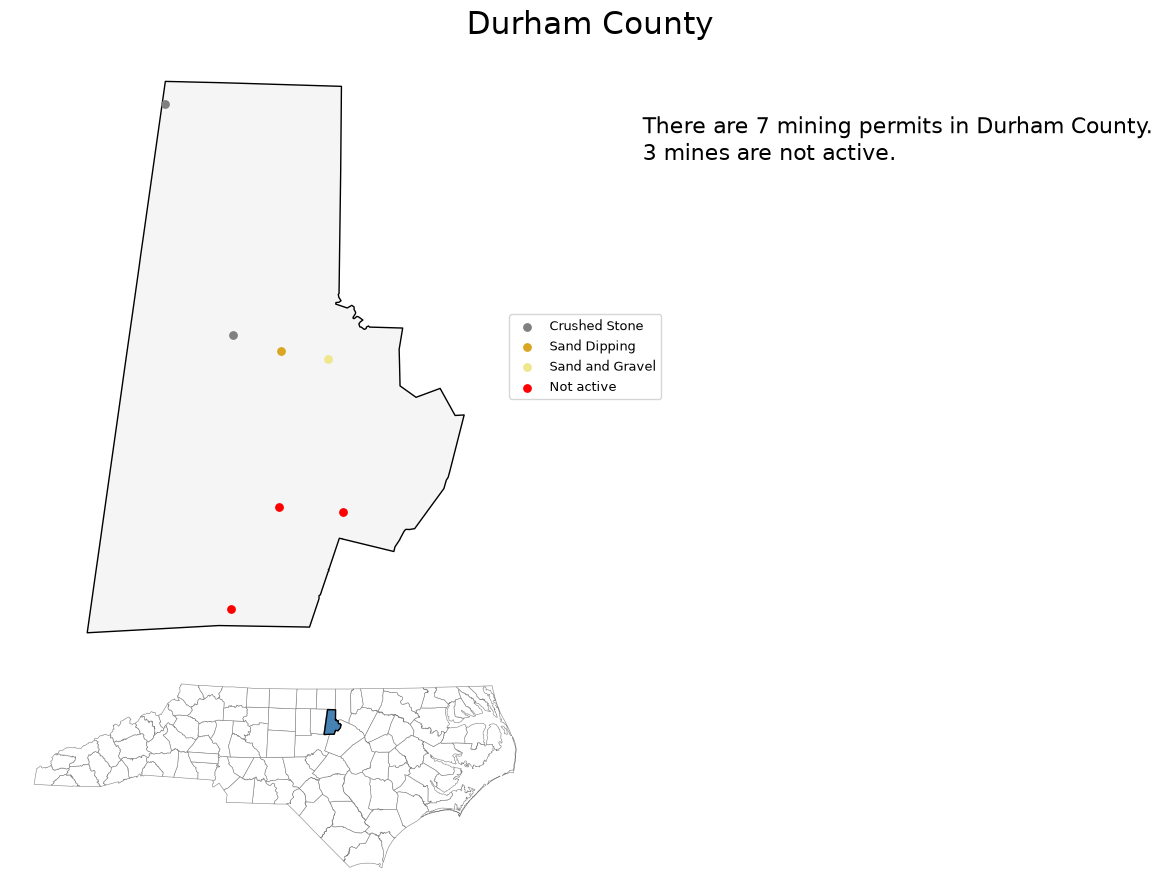

In [22]:
#Test with Durham county
fig, axes = plt.subplots(2, 2, figsize=(12, 9), gridspec_kw={"height_ratios": [3, 1], "width_ratios": [3, 2]})
county_map("Durham", axes[0, 0])
locator_map("Durham", axes[1, 0])
county_info("Durham", axes[0, 1])
axes[1, 1].set_axis_off()
fig.suptitle("Durham County", fontsize=22)
plt.tight_layout()
plt.show()

In [25]:
def county_figure(county, pdf):
    fig = plt.figure(figsize=(8, 10))

    #Large county map on the left
    ax1 = fig.add_axes([0.05, 0.35, 0.62, 0.55])
    county_map(county, ax1)

    #Smaller North Carolina locator underneath
    ax2 = fig.add_axes([0.08, 0.16, 0.35, 0.16])
    locator_map(county, ax2)

    #Text underneath the maps
    ax3 = fig.add_axes([0.06, 0.05, 0.90, 0.10])
    county_info(county, ax3)

    fig.suptitle(county + " County", fontsize=22)

    pdf.savefig(fig)
    plt.close(fig)


In [26]:
with PdfPages("NC_Mining_Atlas.pdf") as pdf:
    for county in nc_counties["NAME"]:
        county_figure(county, pdf)


Notes: Red points include mines marked Inactive, Released, Pending, or Revoked, not just records labeled Inactive. Active mines are colored by commodity type. Mine counts are based on coordinate locations within each county.

Sources: U.S. Census Bureau county boundaries; NC Department of Environmental Quality mining permits.

AI Use: I prompted ChatGPT in order to move the text, NC map, and legend - they were covering each other. It gave me "The fig.add_axes([left, bottom, width, height]) numbers control where each section appears on the page, using values from 0 to 1" and the locations I requested afterward (Big county map, smaller NC map underneath, text under both, legend on the right of the county map)